In [1]:
import pandas as pd
import numpy as np

import autorootcwd  # noqa
from hamilton import driver

from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.model_selection import (
    RandomizedSearchCV,
)
from scipy.stats import randint, loguniform
from sklearn.metrics import roc_auc_score

In [2]:
from src.data.data_splits import (split_cwru_proposed, cwru_optimization_split)
from itertools import combinations, product
import random

In [3]:
def get_cv_splits(
    metadata_df: pd.DataFrame,
    run: int,
    train_side: str = "DE",
    test_size = "2x1"
):
    
    no_duplicate = metadata_df.drop_duplicates(subset=["waveform_id"]).copy()

    train, _ , test = split_cwru_proposed(
        metadata_df=no_duplicate,
        run=run,
        normal_train_side= train_side,
        split_ratio = test_size,
    )
    
    train_idx = train.index.tolist()
    test_idx = test.index.tolist()

    train_df = metadata_df[metadata_df["waveform_id"].isin(train["waveform_id"])]
    train_idx = train_df.index.tolist()
    
    test_df = metadata_df[metadata_df["waveform_id"].isin(test["waveform_id"])]
    test_idx = test_df.index.tolist()

    cv = (train_idx, test_idx)

    return cv

In [4]:
metadata = pd.read_pickle("data/metadata/cwru/files_metadata.bz2")
features = pd.read_parquet("data/features/cwru_features_segmented20.parquet") #  Features with 20 segments of 1s per signal (53% overlap)

In [5]:
metadata.head()

,waveform_id,fault_location,load,rpm,fault_type,fault_size,signal_location,fs,duration,bpfo,bpfi,bsf,ftf,inner,outer,ball,multiclass_label
0,IR_7_DE_DE_48_1HP,DE,1,1772,IR,7,DE,48000,10.129667,3.5848,5.4152,2.35675,0.39828,1,0,0,1
1,IR_7_DE_FE_48_1HP,DE,1,1772,IR,7,FE,48000,10.129667,3.0530,4.9469,1.99370,0.38170,0,0,0,0
2,B_7_DE_DE_12_1HP,DE,1,1772,B,7,DE,12000,10.117500,3.5848,5.4152,2.35675,0.39828,0,0,1,3
3,B_7_DE_FE_12_1HP,DE,1,1772,B,7,FE,12000,10.117500,3.0530,4.9469,1.99370,0.38170,0,0,0,0
4,B_7_DE_BA_12_1HP,DE,1,1772,B,7,BA,12000,10.117500,3.5848,5.4152,4.71350,0.39828,0,0,0,0


In [6]:
df = features.merge(metadata, on="waveform_id", how="left")

In [7]:
df.shape

(2880, 43)

In [8]:
cvs = [get_cv_splits(
    metadata_df=df,
    run=run,
    train_side=side, test_size = "1x2")
 for (run, side) in product(
    range(3,53), ["FE", "DE"])]

In [9]:
len(cvs[0][0])

720

In [10]:
features = [ 'acceleration/rms/global', 'acceleration/pk-pk/global',
       'acceleration/kurt/global', 'acceleration/skewness/global',
       'acceleration/fc/global',
       'envelope/spectralPeak/1.0x-bpfo/500-6000',
       'envelope/spectralPeak/2.0x-bpfo/500-6000',
       'envelope/spectralPeak/3.0x-bpfo/500-6000',
       'envelope/spectralPeak/4.0x-bpfo/500-6000',
       'envelope/spectralPeak/5.0x-bpfo/500-6000',
       'envelope/spectralPeak/1.0x-bpfi/500-6000',
       'envelope/spectralPeak/2.0x-bpfi/500-6000',
       'envelope/spectralPeak/3.0x-bpfi/500-6000',
       'envelope/spectralPeak/4.0x-bpfi/500-6000',
       'envelope/spectralPeak/5.0x-bpfi/500-6000',
       'envelope/spectralPeak/1.0x-bsf/500-6000',
       'envelope/spectralPeak/2.0x-bsf/500-6000',
       'envelope/spectralPeak/3.0x-bsf/500-6000',
       'envelope/spectralPeak/4.0x-bsf/500-6000',
       'envelope/spectralPeak/5.0x-bsf/500-6000']

In [11]:
X = df[features].copy()
y = df[['inner', 'outer', 'ball']].copy()

# Features (segmented)

## RF

In [12]:
best_params = {'ccp_alpha': np.float64(6.368545516399493e-05),
 'criterion': 'entropy',
 'max_depth': 3,
 'max_features': 'log2',
 'min_samples_leaf': 3,
 'min_samples_split': 17,
 'n_estimators': 200}

In [13]:

aucs = []
for cv in cvs:

    X_train = X.iloc[cv[0]]
    X_test = X.iloc[cv[1]]

    y_train = y.iloc[cv[0]]
    y_test = y.iloc[cv[1]]

    model = MultiOutputClassifier(RandomForestClassifier(random_state=42, **best_params), n_jobs=-1)

    model.fit(X_train, y_train)
    y_probas = model.predict_proba(X_test)
    proba_outer = y_probas[1][:, 1]
    proba_inner = y_probas[0][:, 1]
    proba_ball = y_probas[2][:, 1]

    auroc_outer = roc_auc_score(y_test["outer"], proba_outer)
    auroc_inner = roc_auc_score(y_test["inner"], proba_inner)
    auroc_ball = roc_auc_score(y_test["ball"], proba_ball)

    macro_auc = np.mean([auroc_outer, auroc_inner, auroc_ball])
    print(f"Macro AUC: {macro_auc:.4f} | Outer AUC: {auroc_outer:.4f} | Inner AUC: {auroc_inner:.4f} | Ball AUC: {auroc_ball:.4f}")
    aucs.append([macro_auc, auroc_outer, auroc_inner, auroc_ball])

Macro AUC: 0.8804 | Outer AUC: 0.8995 | Inner AUC: 0.8767 | Ball AUC: 0.8650
Macro AUC: 0.8527 | Outer AUC: 0.8685 | Inner AUC: 0.8081 | Ball AUC: 0.8816
Macro AUC: 0.8135 | Outer AUC: 0.6993 | Inner AUC: 0.9034 | Ball AUC: 0.8378
Macro AUC: 0.8513 | Outer AUC: 0.7040 | Inner AUC: 0.9458 | Ball AUC: 0.9041
Macro AUC: 0.7997 | Outer AUC: 0.8152 | Inner AUC: 0.9196 | Ball AUC: 0.6642
Macro AUC: 0.8243 | Outer AUC: 0.8051 | Inner AUC: 0.9408 | Ball AUC: 0.7269
Macro AUC: 0.8053 | Outer AUC: 0.8931 | Inner AUC: 0.8840 | Ball AUC: 0.6387
Macro AUC: 0.7629 | Outer AUC: 0.8026 | Inner AUC: 0.8632 | Ball AUC: 0.6229
Macro AUC: 0.6335 | Outer AUC: 0.5506 | Inner AUC: 0.8137 | Ball AUC: 0.5362
Macro AUC: 0.6837 | Outer AUC: 0.6441 | Inner AUC: 0.7997 | Ball AUC: 0.6074
Macro AUC: 0.8463 | Outer AUC: 0.8928 | Inner AUC: 0.9142 | Ball AUC: 0.7319
Macro AUC: 0.8033 | Outer AUC: 0.8242 | Inner AUC: 0.8535 | Ball AUC: 0.7322
Macro AUC: 0.8574 | Outer AUC: 0.8736 | Inner AUC: 0.9203 | Ball AUC: 0.7783

In [14]:
macro_aucs = [i[0] for i in aucs]
np.mean(macro_aucs), np.std(macro_aucs)

(np.float64(0.8018523390997023), np.float64(0.044262177267528006))

In [15]:
x = [1/3, 2/3]
y = [0.80185, 0.85067]
stds = [0.04426, 0.08921]

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(np.array(x).reshape(-1, 1), y)

coef = model.coef_[0]
intercept = model.intercept_
print(f"Linear regression model: y = {coef:.4f} * x + {intercept:.4f}")

Linear regression model: y = 0.1465 * x + 0.7530


0.33333333333333337 0.849961
0.6666666666666666 0.9442437


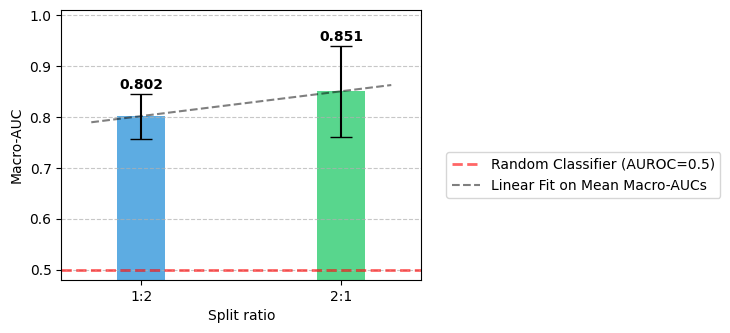

In [16]:
import matplotlib.pyplot as plt

x_line = np.linspace(0.25, 0.75, 200)

y_line = coef * x_line + intercept
split_ratios = ["1:2", "2:1"]

fig, ax = plt.subplots(figsize=(6, 3.5))

bar_colors = ["#3498db", "#2ecc71"]  # blue, green

bars = ax.bar(
    np.array(x),
    y,
    yerr=stds,
    capsize=8,
    color=bar_colors,
    width=0.08,
    alpha=0.8,
)


ax.axhline(
    0.5,
    color="red",
    linestyle="--",
    linewidth=2,
    alpha=0.6,
    label="Random Classifier (AUROC=0.5)",
)

y_line = [coef * i + intercept for i in x_line]
ax.plot(
    x_line,
    y_line,
    color="black",
    linestyle="--",
    linewidth=1.5,
    alpha=0.5,
    label=f"Linear Fit on Mean Macro-AUCs",
)

ax.set_ylabel("Macro-AUC")
ax.set_xlabel("Split ratio")
ax.set_ylim(0.48, 1.01)
ax.set_xlim(0.2, 0.8)
ax.grid(True, axis="y", linestyle="--", alpha=0.7)

ax.set_xticks(x)
ax.set_xticklabels(split_ratios)

for bar, mean, i in zip(bars, y, [0,1]):
    xx = bar.get_x() + bar.get_width() * 0.5
    up_y = bar.get_height()* 0.06 if i == 0 else bar.get_height()* 0.11
    yy = bar.get_height() + up_y
    print(xx, yy)
    ax.text(xx, yy, f"{mean:.3f}", ha="center", va="bottom", fontsize=10, fontweight='bold')


ax.legend(bbox_to_anchor=(1.05, 0.5), loc='upper left', fontsize=10)

fig.subplots_adjust(left=0.15, right=0.75)

# plt.savefig(
#     "notebooks/cwru/cwru_diversity3.pdf",
#     bbox_inches="tight",
#     dpi=600,
#     transparent=True,
# )
plt.show()